# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_:
- _Student No._: 20XX-XXXXX
- _Section_: fill in

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

**Figure 1. Synthetic data interpolation.** Insert a figure comparing the sampled sine data with the linear, nearest, quadratic, and cubic interpolations. TMJA: Include a discussion comparing spline interpolation with curve-fitting.

**Figure 2. Real-world data reconstruction.** Insert the four reconstruction plots for sampling levels of 50%, 30%, 10%, and 5%.

### Report discussion

**Interpolator comparison:** Discuss how the interpolation methods differ and which reproduces the underlying function most accurately for the synthetic data.

The methods fundamentally differ by how they construct the mathematical paths between the random data points. 

1. Nearest - This interpolation method is completely discontinuous at it has vertical jumps (blocky steps) between data points.
2. Linear - This interpolation method is continuous, but the slope (1st derivative) breaks sharply at every data point.
3. Quadratic - This interpolation method has both continuous values and slope.
4. Cubic - This interpolation method as continuous values, slope, and curvature. 



**Sampling-level comparison:** Discuss how reconstruction quality changes as the number of sampled data points decreases. Mention limitations and any visible artifacts.

### Other comments
- EDIT ME
- A self-reflection can be placed here. This portion is not graded.

---
## Section 2: Code

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate #(spline interpolation)

# Initialize random number generator as provided
rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

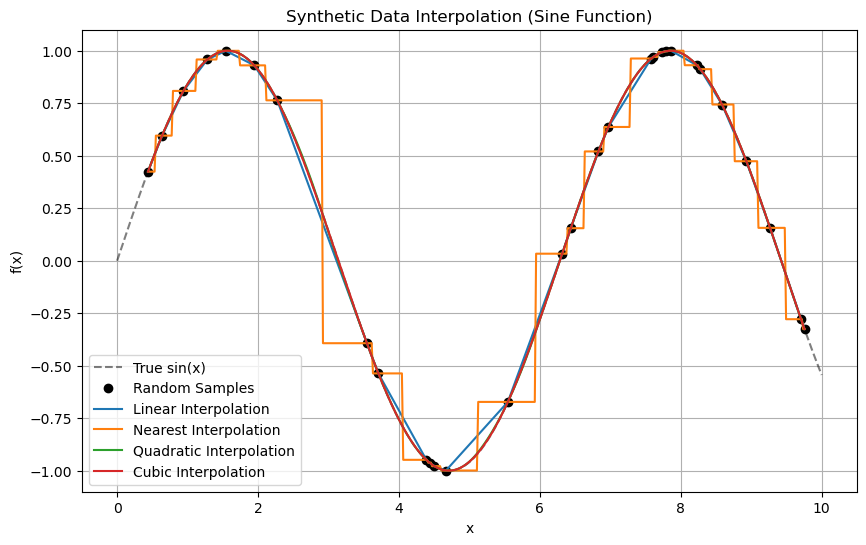

In [39]:

# Define the true sine function
def f(x):
    return np.sin(x)

# Generate the continuous function for reference
x_true = np.linspace(0, 10, 500)
y_true = f(x_true)

# Generate random samples from the domain
# Sorting is required for some interpolation methods
num_samples = 30
x_sampled = np.sort(rng.uniform(0, 10, num_samples))
y_sampled = f(x_sampled)

# Apply different interpolation methods
x_interp = np.linspace(x_sampled.min(), x_sampled.max(), 500)
methods = ['linear', 'nearest', 'quadratic', 'cubic']

plt.figure(figsize=(10, 6))
plt.plot(x_true, y_true, 'k--', label='True sin(x)', alpha=0.5)
plt.plot(x_sampled, y_sampled, 'ko', label='Random Samples', markersize=6)

# Iterate through methods and plot each one

for kind in methods:
    f_interp = interpolate.interp1d(x_sampled, y_sampled, kind=kind)
    plt.plot(x_interp, f_interp(x_interp), label=f'{kind.capitalize()} Interpolation')

plt.title('Synthetic Data Interpolation (Sine Function)')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.savefig('8.1.1.png')
plt.show()

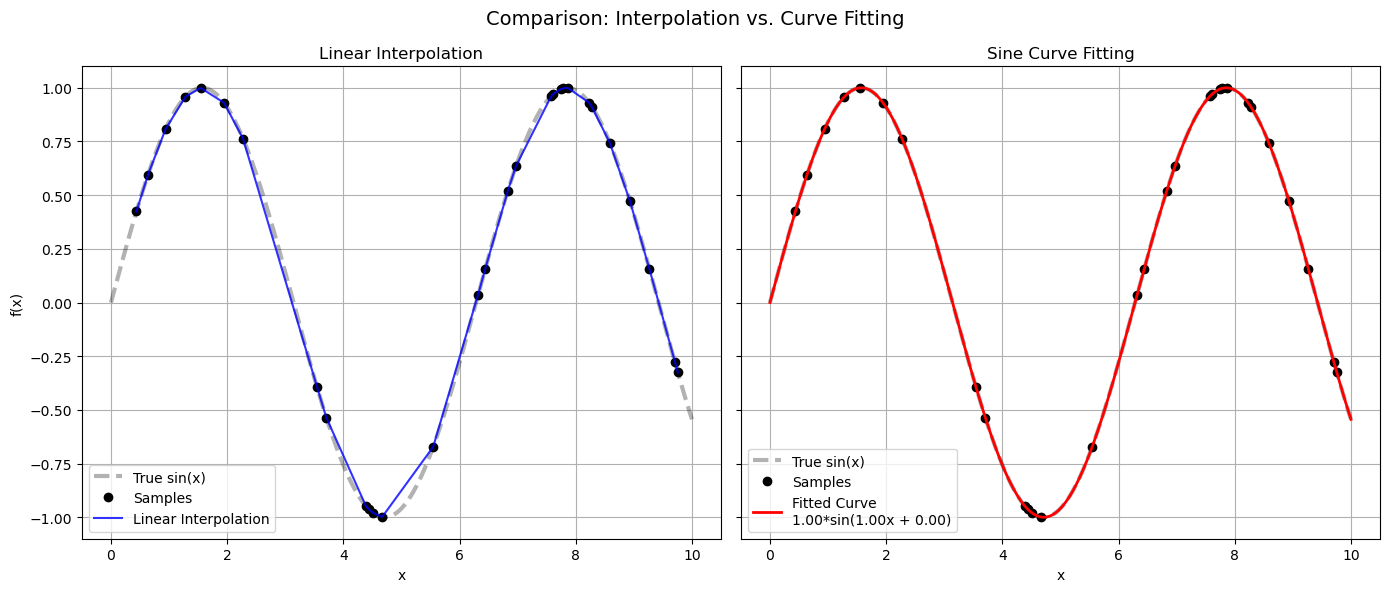

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from scipy.optimize import curve_fit

# Reproduce the exact same sampled points
rng = np.random.default_rng(42)

def f(x):
    return np.sin(x)

x_true = np.linspace(0, 10, 500)
y_true = f(x_true)

num_samples = 30
x_sampled = np.sort(rng.uniform(0, 10, num_samples))
y_sampled = f(x_sampled)

# Linear Interpolation
f_linear = interpolate.interp1d(x_sampled, y_sampled, kind='linear')
x_interp = np.linspace(x_sampled.min(), x_sampled.max(), 500)
y_linear = f_linear(x_interp)

# Curve Fitting
def sine_model(x, amplitude, frequency, phase, offset):
    return amplitude * np.sin(frequency * x + phase) + offset

initial_guess = [1.0, 1.0, 0.0, 0.0]
optimal_params, covariance = curve_fit(sine_model, x_sampled, y_sampled, p0=initial_guess)
y_fitted = sine_model(x_true, *optimal_params)

# Create Side-by-Side Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Plot 1: Cubic Interpolation
ax1.plot(x_true, y_true, 'k--', label='True sin(x)', alpha=0.3, linewidth=3)
ax1.plot(x_sampled, y_sampled, 'ko', label='Samples', markersize=6)
ax1.plot(x_interp, y_linear, 'b-', label='Linear Interpolation', alpha=0.8)
ax1.set_title('Linear Interpolation')
ax1.set_xlabel('x')
ax1.set_ylabel('f(x)')
ax1.legend()
ax1.grid(True)

# Plot 2: Curve Fitting
ax2.plot(x_true, y_true, 'k--', label='True sin(x)', alpha=0.3, linewidth=3)
ax2.plot(x_sampled, y_sampled, 'ko', label='Samples', markersize=6)
ax2.plot(x_true, y_fitted, 'r-', label=f'Fitted Curve\n{optimal_params[0]:.2f}*sin({optimal_params[1]:.2f}x + {optimal_params[2]:.2f})', linewidth=2)
ax2.set_title('Sine Curve Fitting')
ax2.set_xlabel('x')
ax2.legend()
ax2.grid(True)

plt.suptitle('Comparison: Interpolation vs. Curve Fitting', fontsize=14)
plt.tight_layout()
plt.savefig('8.1.2.png')
plt.show()

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [33]:
!wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

In [41]:
import pandas as pd
print(pd.__version__)

2.1.1


In [42]:
df = pd.read_csv('dow.txt', sep='\t')
df.head()

,12121.71
0,12136.44
1,12226.73
2,12221.93
3,12194.13
4,12283.85


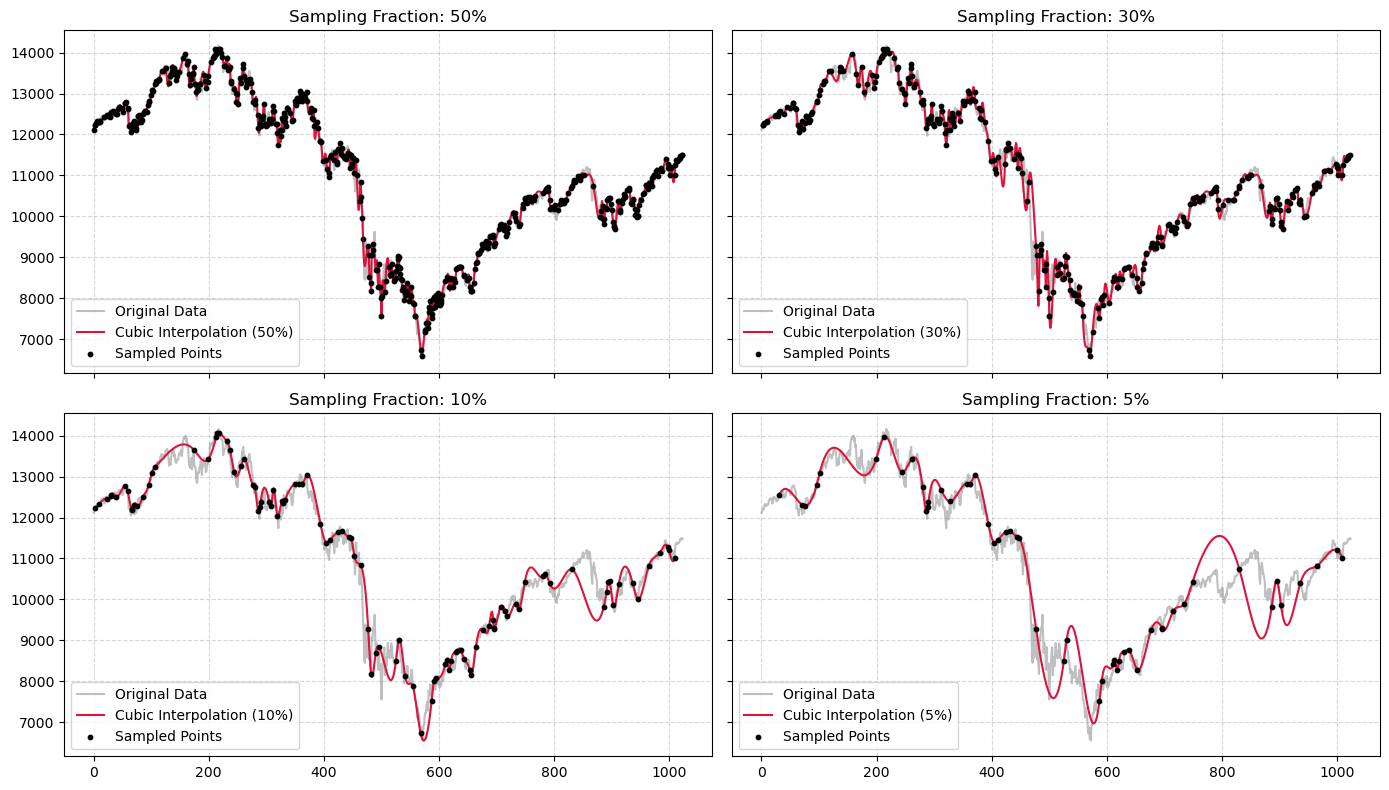

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define sampling fractions
sampling_fractions = [0.50, 0.30, 0.10, 0.05]

df_original = pd.read_csv("dow.txt", header=None, names=["value"])

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
axes = axes.flatten()


for i, frac in enumerate(sampling_fractions):
    # Randomly sample a fraction of observations and sort by original index
    sampled = df_original.sample(frac=frac, random_state=42).sort_index()
    
    # Reindex to full original length 
    reconstructed = sampled.reindex(df_original.index)
    
    # Perform cubic spline interpolation
    reconstructed["cubic_interp"] = reconstructed["value"].interpolate(method="cubic")
    
    # Plot original vs reconstructed
    ax = axes[i]
    ax.plot(df_original.index, df_original["value"], color="gray", alpha=0.5, label="Original Data")
    ax.plot(reconstructed.index, reconstructed["cubic_interp"], color="crimson", linewidth=1.5, label=f"Cubic Interpolation ({int(frac*100)}%)")
    ax.scatter(sampled.index, sampled["value"], color="black", s=10, zorder=3, label="Sampled Points")
    
    ax.set_title(f"Sampling Fraction: {int(frac*100)}%")
    ax.legend(loc="lower left")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig('8.2.png')
plt.show()

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

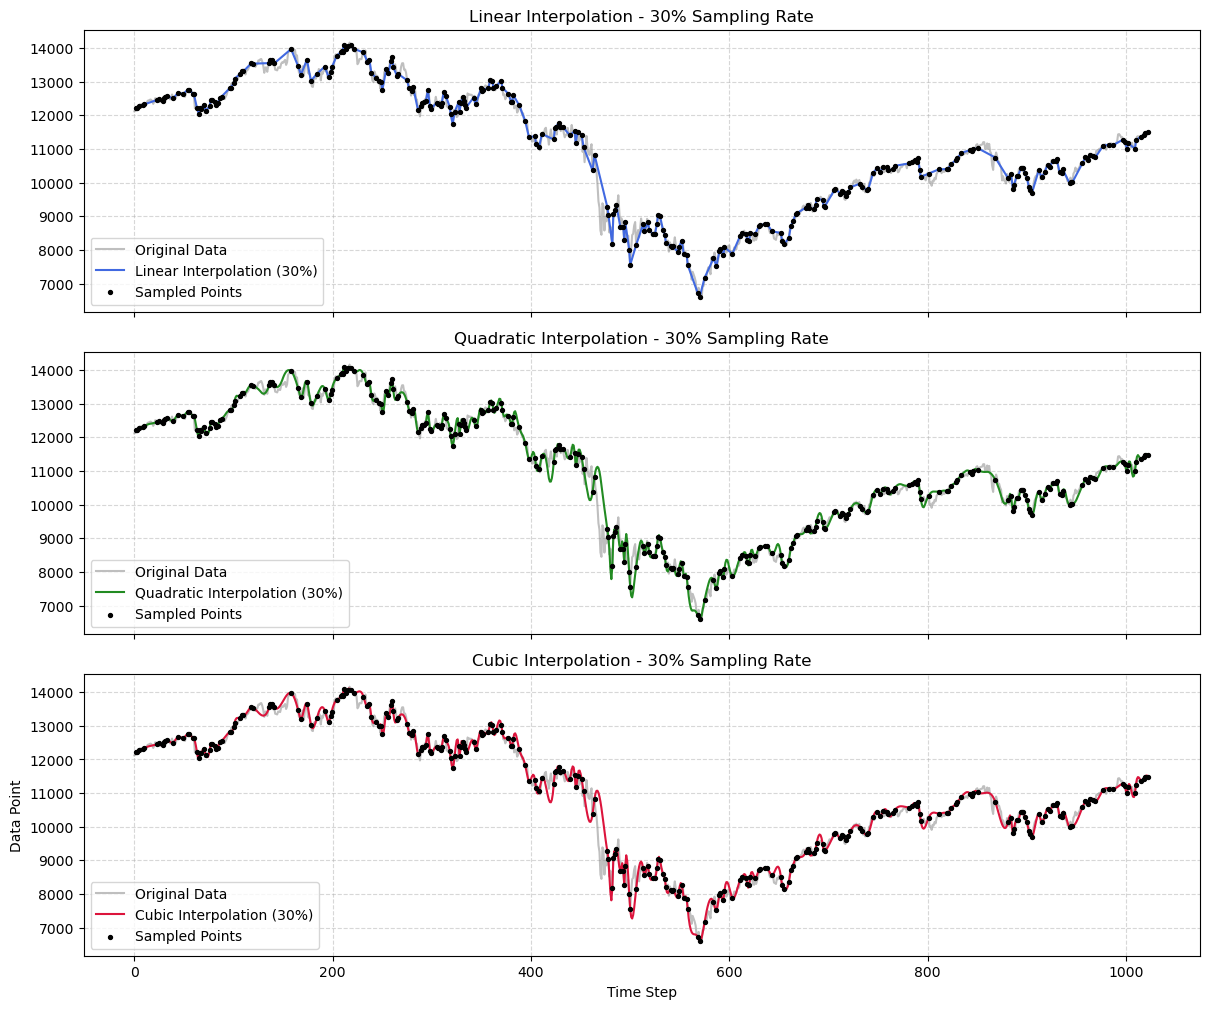

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df_original = pd.read_csv("dow.txt", header=None, names=["value"])

frac = 0.30
sampled = df_original.sample(frac=frac, random_state=42).sort_index()

# this is for the placeholder gaps that the interpolation methods will fill
reconstructed = sampled.reindex(df_original.index)

# Perform the 3 interpolation methods
reconstructed["linear_interp"] = reconstructed["value"].interpolate(method="linear")
reconstructed["quadratic_interp"] = reconstructed["value"].interpolate(method="quadratic")
reconstructed["cubic_interp"] = reconstructed["value"].interpolate(method="cubic")

# Define methods and colors to loop over
methods = [
    ("linear_interp", "Linear Interpolation", "royalblue"),
    ("quadratic_interp", "Quadratic Interpolation", "forestgreen"),
    ("cubic_interp", "Cubic Interpolation", "crimson")
]

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, sharey=True)

# Loop over each interpolation method and plot on its corresponding axis
for i, (col, title, color) in enumerate(methods):
    ax = axes[i]
    ax.plot(df_original.index, df_original["value"], color="gray", alpha=0.5, label="Original Data")
    ax.plot(reconstructed.index, reconstructed[col], color=color, linewidth=1.5, label=f"{title} (30%)")
    ax.scatter(sampled.index, sampled["value"], color="black", s=8, zorder=3, label="Sampled Points")
    
    ax.set_title(f"{title} - 30% Sampling Rate")
    ax.legend(loc="lower left")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig('8.3.png')
plt.xlabel("Time Step")
plt.ylabel("Data Point")
plt.show()

### Problem  code summary


The code utilizes four interpolation methods (nearest, linear, quadratic, and cubic) to estimate 

---